# **Part A: Conceptual Understanding (Theory)**

## 1. What are Supervised Learning Algorithms?

Supervised Learning Algorithms are machine learning algorithms that learn from labeled data.  
In this type of learning, the input data and correct output are already given to the model during training.

The algorithm studies the relationship between input and output and then predicts results for new data.

Supervised learning is mainly used for:
- Prediction
- Classification
- Forecasting

Examples:
- Linear Regression
- Logistic Regression
- Decision Tree
- Random Forest
- Support Vector Machine (SVM)

Example:
If we give a model house features and their prices, it learns the pattern and predicts the price of a new house.

---

## 2. Difference between Regression Algorithms vs Classification Algorithms

| Regression Algorithms | Classification Algorithms |
|---|---|
| Used to predict continuous values | Used to predict categories or classes |
| Output is numeric | Output is categorical |
| Example: Predicting house price | Example: Predicting spam or not spam |
| Used when target variable is continuous | Used when target variable is discrete |
| Examples: Linear Regression, Polynomial Regression | Examples: Logistic Regression, Decision Tree |

Example:
- Regression → Predicting salary amount
- Classification → Predicting pass/fail

---

## 3. Explain Simple Linear Regression

Simple Linear Regression is a supervised learning algorithm used to find the relationship between one independent variable and one dependent variable.

It predicts continuous values using a straight-line equation.

The equation is:

y = mx + c

Where:
- y = dependent variable
- x = independent variable
- m = slope of line
- c = intercept

The main objective is to find the best-fit line that minimizes prediction error.

Example:
Predicting house price based on area of the house.

If area increases, price may also increase.

---

## 4. List and Explain the Assumptions of Linear Regression

### 1. Linear Relationship
There should be a linear relationship between independent and dependent variables.

Example:
As house area increases, house price should increase proportionally.

---

### 2. Independence of Errors
The errors should not depend on each other.

Each observation should be independent.

---

### 3. Homoscedasticity
The variance of errors should remain constant for all values.

Errors should not increase or decrease too much.

---

### 4. Normal Distribution of Errors
The residual errors should be normally distributed.

This helps improve prediction accuracy.

---

### 5. No Multicollinearity
Independent variables should not be highly correlated with each other.

Example:
Using both monthly salary and yearly salary together may create multicollinearity.

---

## 5. What is Bias-Variance Trade-Off?

Bias-Variance Trade-Off is the balance between underfitting and overfitting in machine learning.

### Bias
- Bias occurs when the model is too simple and cannot learn the data properly.
- High bias leads to underfitting.

---

### Variance
- Variance occurs when the model learns too much from training data, including noise.
- High variance leads to overfitting.

---

A good model should maintain a balance between bias and variance to achieve better accuracy on new data.

---

## 6. Explain Overfitting and Underfitting with Examples

### Underfitting
Underfitting happens when the model is too simple and cannot learn the training data properly.

Characteristics:
- Poor training accuracy
- Poor testing accuracy

Example:
Using a straight line to predict complex curved data.

---

### Overfitting
Overfitting happens when the model learns the training data too perfectly, including noise and unnecessary details.

Characteristics:
- Very high training accuracy
- Poor testing accuracy

Example:
A model memorizing exact training examples instead of learning patterns.

---

### Ideal Fit
An ideal model learns important patterns from data and performs well on both training and testing data.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

# **Part B: Dataset Understanding & Preparation**

In [24]:
df = pd.read_csv('RealEstate_HousePrice_Dataset_4200.csv')

In [25]:
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


In [27]:
X = df.drop(["house_id", "house_price_inr"], axis = 1)
y = df["house_price_inr"]

print("Independent Variables:")
print(X.columns)

print("\nDependent Variable:", y.name)

Independent Variables:
Index(['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years',
       'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool',
       'renovation_years_ago'],
      dtype='object')

Dependent Variable: house_price_inr


In [28]:
X.head()

,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago
0,1973,5,4,7.6,23,11.9,5220,1,0,0
1,1560,3,3,6.3,13,15.8,3882,1,0,13
2,2071,4,3,5.8,9,21.1,4488,0,0,9
3,2640,5,3,7.7,12,7.9,3614,1,1,4
4,1498,3,3,3.8,15,24.0,2663,0,0,15


In [29]:
y.head()

0    40275084
1    26812029
2    29315677
3    47712959
4    17724566
Name: house_price_inr, dtype: int64

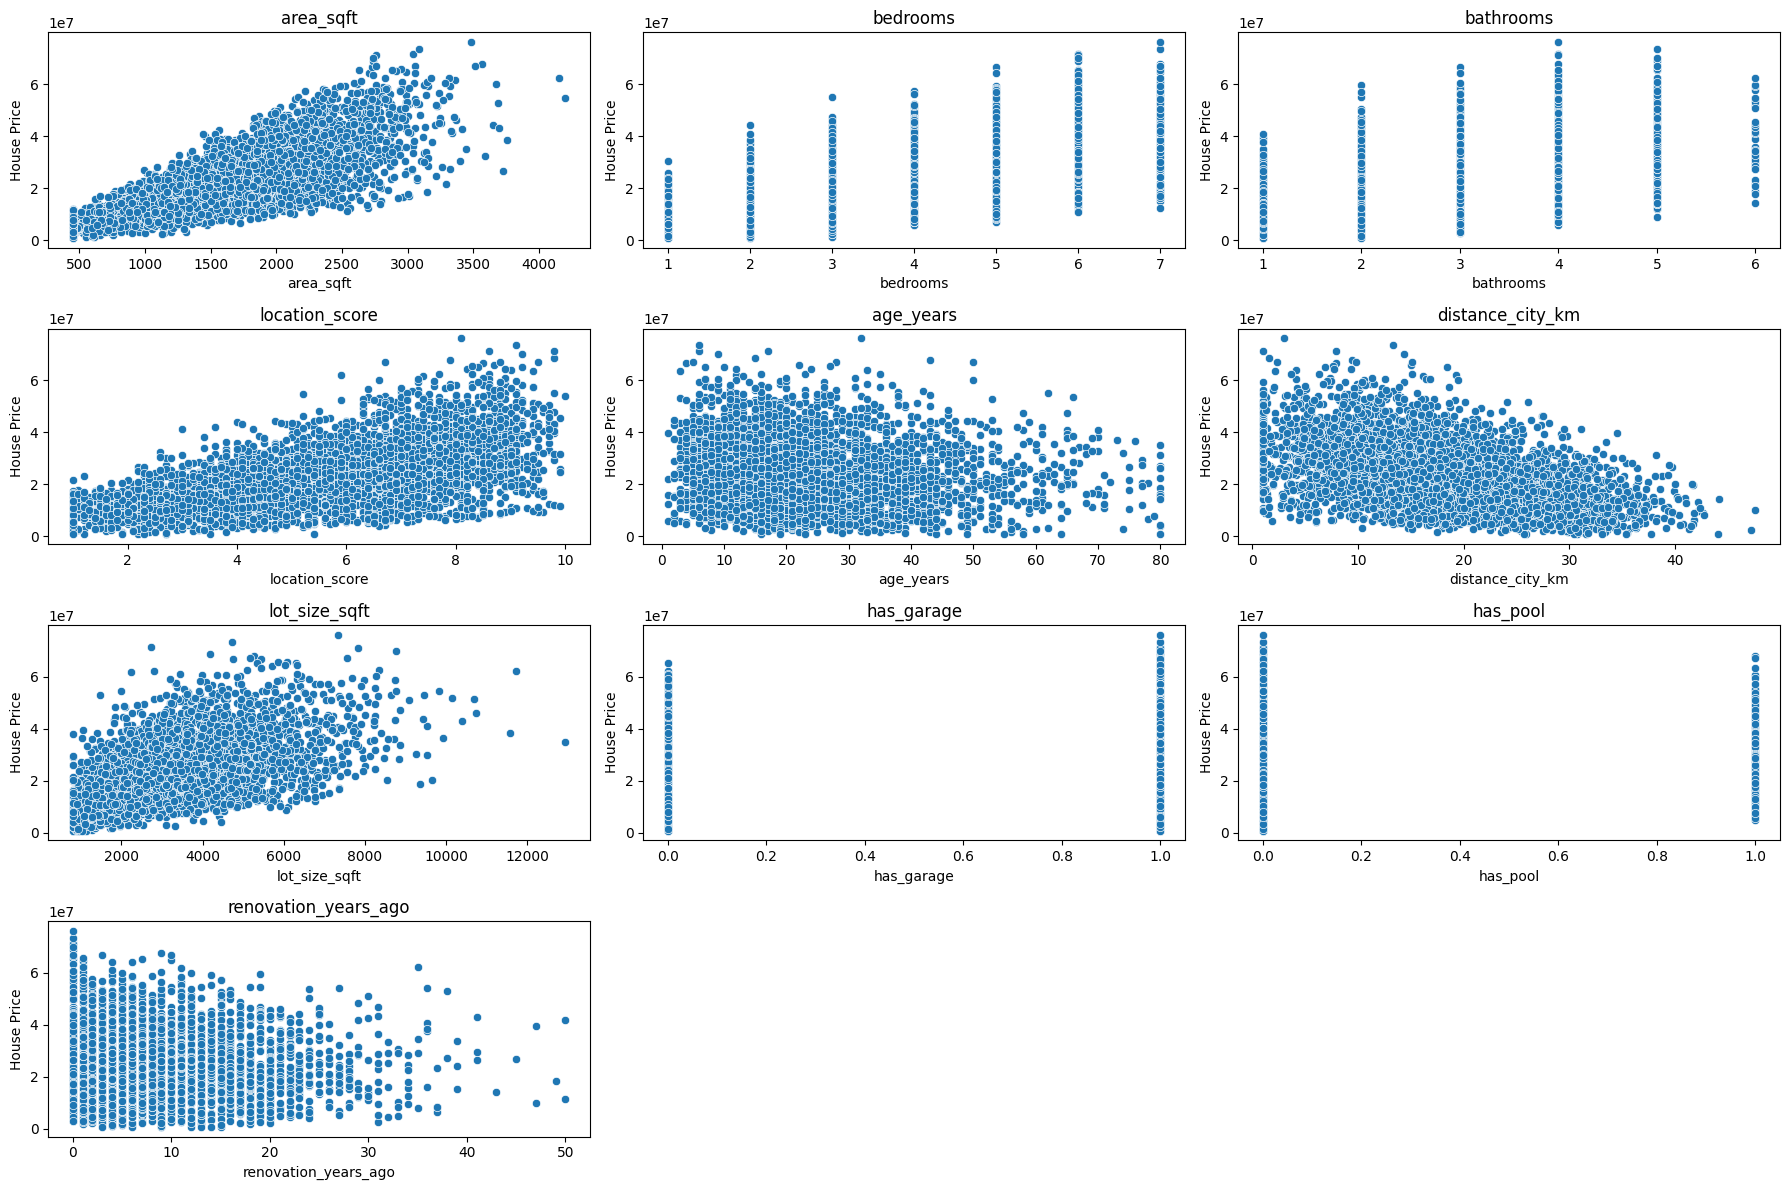

In [ ]:
# Relationships b/w features & target variable

plt.figure(figsize=(18, 12))

plot_number = 1

for feature in X:
    
    plt.subplot(4, 3, plot_number)
    
    sns.scatterplot(
        x=df[feature],
        y=df["house_price_inr"]
    )
    
    plt.xlabel(feature)
    plt.ylabel("House Price")
    plt.title(feature)
    
    plot_number += 1

plt.tight_layout()
plt.show()

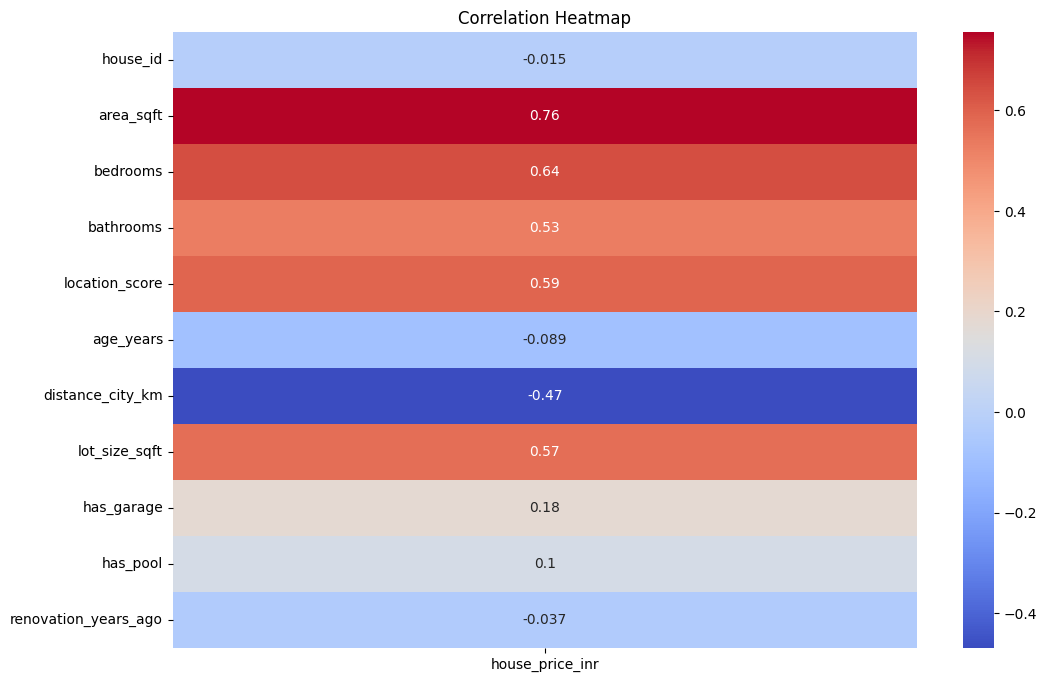

In [44]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr()[["house_price_inr"]].drop("house_price_inr"), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [32]:
# Splitting data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# **Part C: Simple Linear Regression**

In [33]:
X_simple = df[["area_sqft"]]
y_simple = df[["house_price_inr"]]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42)

simple_model = LinearRegression()

simple_model.fit(X_train_s, y_train_s)

y_pred_simple = simple_model.predict(X_test_s)

In [34]:
print("Slope:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

Slope: [14788.30611131]
Intercept: [-1163519.1764186]


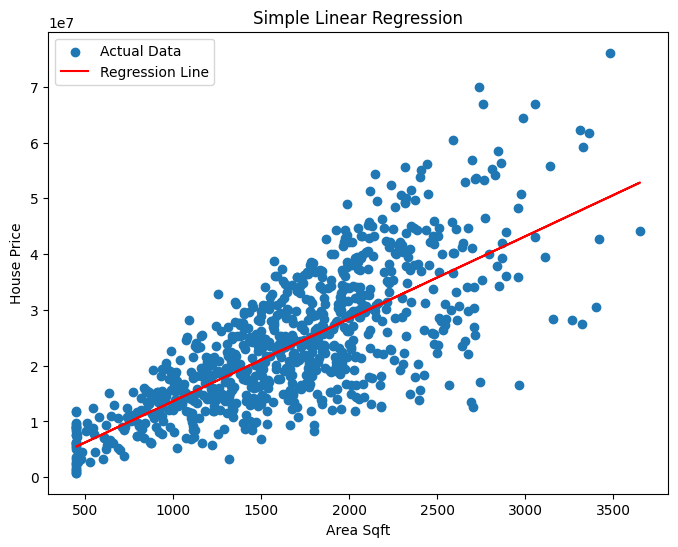

In [35]:
plt.figure(figsize=(8,6))

plt.scatter(X_test_s, y_test_s, label="Actual Data")
plt.plot(X_test_s, y_pred_simple, label="Regression Line", color = "red")
plt.xlabel("Area Sqft")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

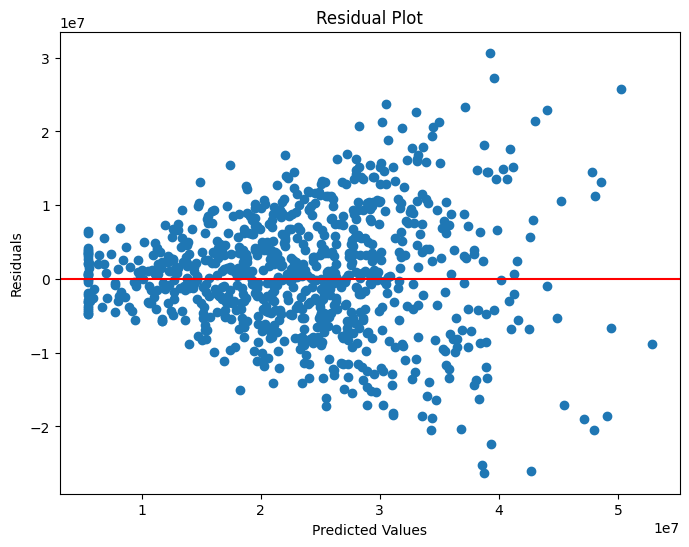

In [45]:
# Find Residuals
residuals = y_test_s - y_pred_simple

# Residual Plot
plt.figure(figsize=(8,6))
plt.scatter(y_pred_simple, residuals)
plt.axhline(y=0, color="red")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

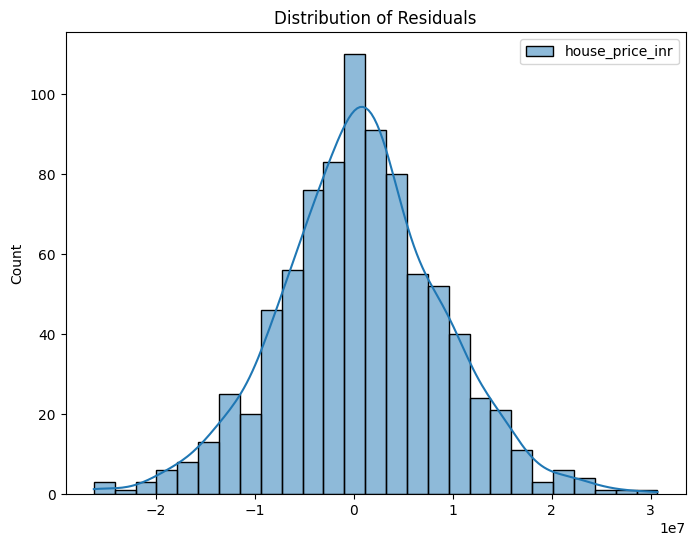

In [36]:
# Residual Distribution
plt.figure(figsize=(8,6))
sns.histplot(residuals, kde=True)
plt.title("Distribution of Residuals")
plt.show()

### Residual Plot Observation

- The residual plot shows that the points are scattered around the zero line, which is a good sign for Linear Regression.

- However, the spread of residuals increases as the predicted values increase, creating a funnel/V-shaped pattern.

- This indicates slight heteroscedasticity, meaning the variance of errors is not completely constant.

---

### Distribution Plot Observation
- The distribution of residuals is approximately bell-shaped.

- This indicates that the residuals are nearly normally distributed, which satisfies one of the important assumptions of Linear Regression.

---

### Conclusion
The Linear Regression model satisfies the normality assumption reasonably well, but there may be slight variance inconsistency visible in the residual plot.

# **Part D: Model Evaluation Metrics**

In [37]:
slr_mse = mean_squared_error(y_test_s, y_pred_simple)
slr_mae = mean_absolute_error(y_test_s, y_pred_simple)
slr_rmse = np.sqrt(slr_mse)
slr_r2 = r2_score(y_test_s, y_pred_simple)

n = len(y_test_s)
p = 1

slr_adjusted_r2 = 1 - ((1 - slr_r2) * (n - 1) / (n - p - 1))

print("Mean Squared Error:", slr_mse)
print("Mean Absolute Error:", slr_mae)
print("Root Mean Squared Error:", slr_rmse)
print("R2 Score:", slr_r2)
print("Adjusted R2 Score:", slr_adjusted_r2)

Mean Squared Error: 66989260021849.47
Mean Absolute Error: 6294593.696131912
Root Mean Squared Error: 8184696.696997969
R2 Score: 0.5625199587991578
Adjusted R2 Score: 0.5619979062440257


# **Part E: Multiple Linear Regression**

In [38]:
X_multi = X

y_multi = y

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

multi_model = LinearRegression()

multi_model.fit(X_train_m, y_train_m)

y_pred_multi = multi_model.predict(X_test_m)

In [100]:
multi_mae = mean_absolute_error(y_test_m, y_pred_multi)
multi_r2 = r2_score(y_test_m, y_pred_multi)
multi_mse = mean_squared_error(y_test_m, y_pred_multi)
multi_rmse = np.sqrt(multi_mse)

n = len(y_test_m)
p = 1
multi_adjusted_r2 = 1 - ((1 - multi_r2) * (n - 1) / (n - p - 1))

# Metrics
print("Mean Squared Error:", multi_mse)
print("Mean Absolute Error:", multi_mae)
print("Root Mean Squared Error:", multi_rmse)
print("R2 Score:", multi_r2)
print("Adjusted R2 Score:", multi_adjusted_r2)
print("-"*30)
# Compariosn
print("Simple Linear Regression R2 Score:", slr_r2)
print("Multiple Linear Regression R2 Score:", multi_r2)

Mean Squared Error: 12592918884127.742
Mean Absolute Error: 2604991.406155695
Root Mean Squared Error: 3548650.290480557
R2 Score: 0.917760687750989
Adjusted R2 Score: 0.9176625501468731
------------------------------
Simple Linear Regression R2 Score: 0.5625199587991578
Multiple Linear Regression R2 Score: 0.917760687750989


- Multiple Linear Regression usually performs better because it uses multiple features instead of only one feature.
- More information helps improve prediction accuracy.

# **Part F: Polynomial Regression**

In [101]:
# Polynomial Regression

poly = PolynomialFeatures(degree=3)

X_train_poly = poly.fit_transform(X_train_s)
X_test_poly = poly.transform(X_test_s)

poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train_s)

y_pred_poly = poly_model.predict(X_test_poly)

In [102]:
# Metrics

poly_mse = mean_squared_error(y_test_s, y_pred_poly)
poly_mae = mean_absolute_error(y_test_s, y_pred_poly)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(y_test_s, y_pred_poly)

n = len(y_test_s)
p = 1
poly_adjusted_r2 = 1 - ((1 - poly_r2) * (n - 1) / (n - p - 1))

print("Mean Squared Error:", poly_mse)
print("Mean Absolute Error:", poly_mae)
print("Root Mean Squared Error:", poly_rmse)
print("R2 Score:", poly_r2)
print("Adjusted R2 Score:", poly_adjusted_r2)

Mean Squared Error: 66935016201493.336
Mean Absolute Error: 6289615.314592113
Root Mean Squared Error: 8181382.291611445
R2 Score: 0.5628742034759397
Adjusted R2 Score: 0.5623525736471521


Simple Linear Regression R2: 0.5625199587991578
Polynomial Regression R2: 0.5628742034759397


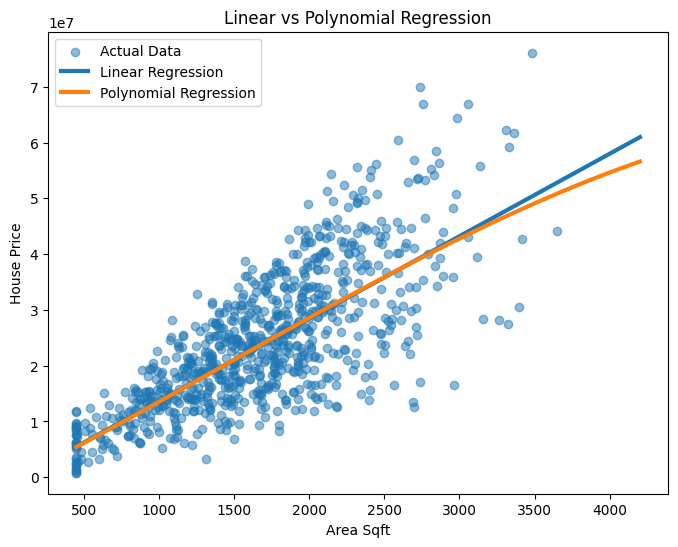

In [ ]:
# Compare Linear vs Polynomial Regression

print("Simple Linear Regression R2:", slr_r2)
print("Polynomial Regression R2:", poly_r2)

# Values for plotting
X_curve = pd.DataFrame({"area_sqft": np.linspace(X_simple["area_sqft"].min(), X_simple["area_sqft"].max(), 500)})

# Linear Regression Line
y_curve_linear = simple_model.predict(X_curve)

# Polynomial Regression Curve
X_curve_poly = poly.transform(X_curve)

y_curve_poly = poly_model.predict(X_curve_poly)

plt.figure(figsize=(8,6))

# Actual Data
plt.scatter(X_test_s, y_test_s, alpha=0.5, label="Actual Data")

# Linear Regression
plt.plot(X_curve, y_curve_linear, linewidth=3, label="Linear Regression")

# Polynomial Regression
plt.plot(X_curve, y_curve_poly, linewidth=3, label="Polynomial Regression")

plt.xlabel("Area Sqft")
plt.ylabel("House Price")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()

In [ ]:
# Model Comparison

print("Simple Linear Regression R2:", slr_r2)

print("Multiple Linear Regression R2:", multi_r2)

print("Polynomial Regression (Single Feature) R2:", poly_r2)

Simple Linear Regression R2: 0.5625199587991578
Multiple Linear Regression R2: 0.917760687750989
Polynomial Regression (Single Feature) R2: 0.5628742034759397


### Observation

The graph shows that both models follow a similar trend, with the Polynomial Regression curve being slightly more flexible.

Since the R² scores are very close, Polynomial Regression does not provide a significant improvement over Linear Regression for this dataset.

### Signs of Overfitting or Underfitting

The Polynomial Regression model with degree 3 does not show major overfitting or underfitting.

The R² scores of Linear Regression and Polynomial Regression are almost the same:

- Linear Regression R² = 0.5625
- Polynomial Regression R² = 0.5629

This shows that increasing the polynomial degree did not significantly improve the model performance.

In the graph, both regression lines are very close to each other, and the Polynomial Regression curve is smooth without excessive bending.

Therefore:
- No strong overfitting is observed because the polynomial curve is not highly fluctuating.
- No major underfitting is observed because the model is still capturing the general increasing trend between area and house price.

The dataset mainly follows a linear relationship, so Polynomial Regression does not provide much additional benefit.

# **Part G: Gradient Descent Optimization**

### Explain Gradient Descent Conceptually

Gradient Descent is an optimization algorithm used to minimize the error or cost function in Machine Learning.

It works by repeatedly updating model parameters in the direction where the error decreases the fastest.

The algorithm calculates the gradient (slope) of the cost function and moves step-by-step toward the minimum error.

The update formula is:

θ = θ − α × gradient

Where:
- θ = model parameter
- α = learning rate
- gradient = slope of cost function

The main objective of Gradient Descent is to find the best parameter values that reduce prediction error.

In [81]:
# Data

x = X_train_s["area_sqft"].values
y = y_train_s.values.flatten()

# Standardization
x = (x - x.mean()) / x.std()
y = (y - y.mean()) / y.std()

x = x.reshape(-1, 1)

In [82]:
# Batch Gradient Descent

m = 0.0
c = 0.0

learning_rate = 0.05
iterations = 500

n = len(x)

start_time = time.perf_counter()

for i in range(iterations):

    y_pred = m * x.flatten() + c

    error = y - y_pred

    cost = np.mean(error**2)

    dm = (-2/n) * np.sum(x.flatten() * error)
    dc = (-2/n) * np.sum(error)

    m -= learning_rate * dm
    c -= learning_rate * dc

end_time = time.perf_counter()

bgd_time = end_time - start_time

print(
    f"BGD - Iteration {iterations}: "
    f"m={m:.4f}, "
    f"c={c:.4f}, "
    f"cost={cost:.4f}, "
    f"time={bgd_time:.4f} seconds"
)

BGD - Iteration 500: m=0.7565, c=0.0000, cost=0.4277, time=0.0123 seconds


In [88]:
# Stochastic Gradient Descent

start_time = time.perf_counter()

sgd_model = SGDRegressor(max_iter=50, eta0=0.01, learning_rate="constant", penalty=None, random_state=42)

sgd_model.fit(x, y)

end_time = time.perf_counter()

sgd_time = end_time - start_time

y_pred_sgd = sgd_model.predict(x)

sgd_cost = np.mean((y - y_pred_sgd) ** 2)

print(
    f"SGD - Epoch 50: "
    f"m={sgd_model.coef_[0]:.4f}, "
    f"c={sgd_model.intercept_[0]:.4f}, "
    f"cost={sgd_cost:.4f}, "
    f"time={sgd_time:.4f} seconds"
)

SGD - Epoch 50: m=0.7123, c=-0.0617, cost=0.4335, time=0.0015 seconds


In [103]:
# Mini Batch Gradient Descent

batch_size = 32

mini_batch_model = SGDRegressor(max_iter=1, eta0=0.01, learning_rate="constant", penalty=None, warm_start=True, random_state=42)

start_time = time.perf_counter()

for epoch in range(100):

    for i in range(0, len(x), batch_size):

        X_batch = x[i:i+batch_size]
        y_batch = y[i:i+batch_size]

        mini_batch_model.partial_fit(X_batch, y_batch)

end_time = time.perf_counter()

mbgd_time = end_time - start_time

y_pred_mbgd = mini_batch_model.predict(x)

mbgd_cost = np.mean((y - y_pred_mbgd) ** 2)

print(
    f"Mini-Batch - Epoch 100: "
    f"m={mini_batch_model.coef_[0]:.4f}, "
    f"c={mini_batch_model.intercept_[0]:.4f}, "
    f"cost={mbgd_cost:.4f}, "
    f"time={mbgd_time:.4f} seconds"
)

Mini-Batch - Epoch 100: m=0.8721, c=0.0464, cost=0.4432, time=2.8046 seconds


In [91]:
# Compare

print("\nGradient Descent Comparison")

print(
    f"BGD       : cost={cost:.4f}, "
    f"time={bgd_time:.4f} sec"
)

print(
    f"SGD       : cost={sgd_cost:.4f}, "
    f"time={sgd_time:.4f} sec"
)

print(
    f"Mini-Batch: cost={mbgd_cost:.4f}, "
    f"time={mbgd_time:.4f} sec"
)


Gradient Descent Comparison
BGD       : cost=0.4277, time=0.0123 sec
SGD       : cost=0.4335, time=0.0015 sec
Mini-Batch: cost=0.4432, time=2.8276 sec


# **Part H: Bias-Variance & Model Diagnostics**

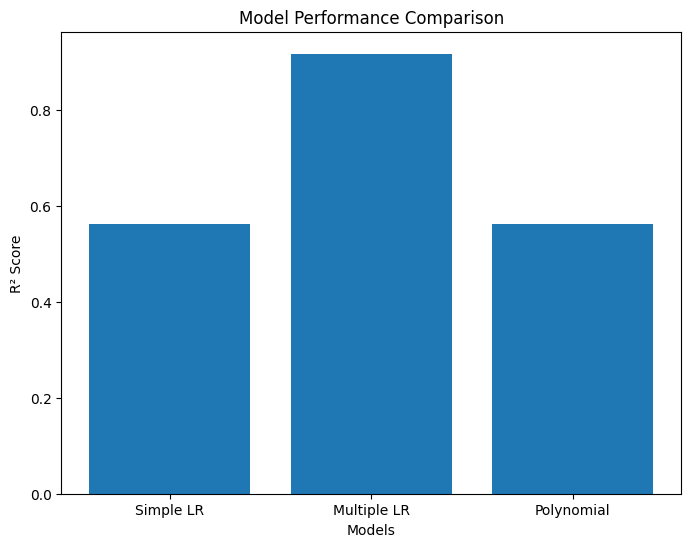

In [ ]:
# Bias-Variance Analysis

models = ["Simple LR", "Multiple LR", "Polynomial"]

r2_scores = [slr_r2, multi_r2, poly_r2]

plt.figure(figsize=(8,6))

plt.bar(models, r2_scores)

plt.xlabel("Models")
plt.ylabel("R² Score")

plt.title("Model Performance Comparison")

plt.show()

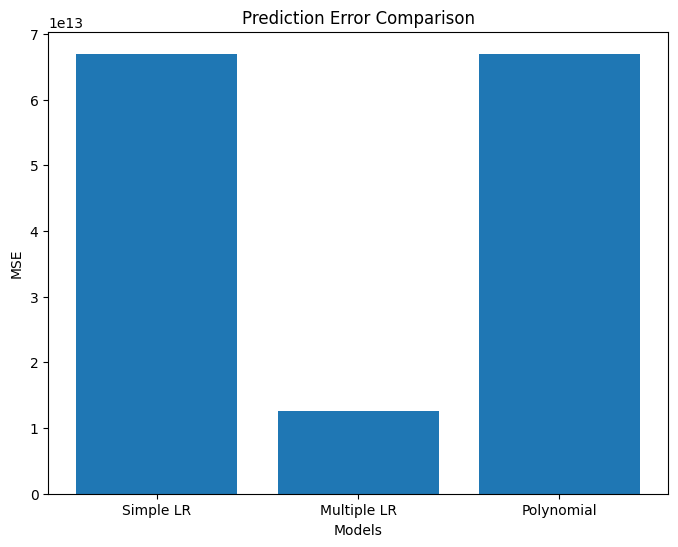

In [ ]:
models = ["Simple LR", "Multiple LR", "Polynomial"]

mse_scores = [slr_mse, multi_mse, poly_mse]

plt.figure(figsize=(8,6))

plt.bar(models, mse_scores)

plt.xlabel("Models")
plt.ylabel("MSE")

plt.title("Prediction Error Comparison")

plt.show()

## 26. Analyze Bias and Variance Across Models

## Simple Linear Regression

Simple Linear Regression uses only one feature (house area) to predict house price.

Since the model is very simple, it has high bias and low variance. It may miss important relationships present in the data.

---

## Multiple Linear Regression

Multiple Linear Regression uses several features such as bedrooms, bathrooms, location score, and lot size.

This reduces bias because the model has access to more information while maintaining reasonable variance.

---

## Polynomial Regression

Polynomial Regression introduces additional polynomial terms, increasing model complexity.

This reduces bias further but may increase variance if the degree becomes too large.

For this dataset, Polynomial Regression provides only a small improvement(as only 1 feature is used), indicating limited non-linear relationships.

### 27. Explain How Model Complexity Affects Prediction Error

As model complexity increases, bias generally decreases because the model can learn more patterns from the data.

However, variance increases because the model may start learning noise and unnecessary details.

A very simple model may underfit the data, while a very complex model may overfit the data.

The goal is to find a model that minimizes both bias and variance to achieve the best prediction performance.

## 28. Identify Which Model Best Balances Bias and Variance

Multiple Linear Regression provides the best balance between bias and variance.

It achieves a significantly higher R² score than Simple Linear Regression while avoiding the unnecessary complexity of higher-degree Polynomial Regression.

Simple Linear Regression shows higher bias because it uses only one feature.

Polynomial Regression increases complexity but provides little additional improvement for this dataset.

Therefore, Multiple Linear Regression is the most suitable model for predicting house prices in this dataset.

# **Part I: Final Analysis & Reporting**

## 29. Final Report

### Best-Performing Model and Why

Among all the models implemented, Multiple Linear Regression performed the best.

| Model | R² Score |
|---------|---------|
| Simple Linear Regression | 0.5625 |
| Multiple Linear Regression | 0.9178 |
| Polynomial Regression | 0.5629 |

Multiple Linear Regression achieved the highest R² score (0.9178) and the lowest error values (MSE, MAE, and RMSE). This indicates that house prices depend on multiple factors such as area, bedrooms, bathrooms, location score, distance from the city, lot size, garage availability, and pool availability rather than area alone.

---

### Impact of Gradient Descent Optimization

Three optimization techniques were implemented:

| Method | Cost | Training Time (seconds) |
|----------|----------|----------|
| Batch Gradient Descent | 0.4277 | 0.0123 |
| Stochastic Gradient Descent | 0.4335 | 0.0015 |
| Mini-Batch Gradient Descent | 0.4432 | 2.8276 |

Batch Gradient Descent achieved the lowest cost value, indicating the most accurate convergence. Stochastic Gradient Descent trained the fastest but showed slightly higher error due to frequent parameter updates. Mini-Batch Gradient Descent provided a balance between the two approaches but required more training time in this implementation.

---

### Evidence of Overfitting or Underfitting

Simple Linear Regression showed signs of underfitting because it used only one feature (house area) and achieved a relatively low R² score.

Polynomial Regression did not significantly improve performance over Simple Linear Regression. The R² score increased only from 0.5625 to 0.5629, indicating that the relationship between house area and house price is largely linear.

No strong evidence of overfitting was observed because the Polynomial Regression model did not produce unusually high accuracy or unstable predictions.

Multiple Linear Regression provided the best balance between bias and variance and achieved the highest predictive performance.

---

### Practical Business Interpretation

The analysis shows that house prices are influenced by several factors rather than just house area.

Features such as:
- Number of bedrooms
- Number of bathrooms
- Location score
- Distance from the city
- Lot size
- Garage availability
- Pool availability

contribute significantly to house price prediction.

Real-estate companies can use the Multiple Linear Regression model to estimate house prices more accurately and support pricing, investment, and valuation decisions.

## 30. Submission

### Source Code

The project includes Python implementations of:

- Simple Linear Regression
- Multiple Linear Regression
- Polynomial Regression
- Batch Gradient Descent
- Stochastic Gradient Descent
- Mini-Batch Gradient Descent

---

### Model Evaluation Results

#### Simple Linear Regression

- MSE = 66,989,260,021,849.47
- MAE = 6,294,593.70
- RMSE = 8,184,696.70
- R² = 0.5625
- Adjusted R² = 0.5620

#### Multiple Linear Regression

- MSE = 12,592,918,884,127.74
- MAE = 2,604,991.41
- RMSE = 3,548,650.29
- R² = 0.9178
- Adjusted R² = 0.9177

#### Polynomial Regression

- MSE = 66,935,016,201,493.34
- MAE = 6,289,615.31
- RMSE = 8,181,382.29
- R² = 0.5629
- Adjusted R² = 0.5624

---

### Graphs and Plots

The following visualizations were generated:

- Feature vs House Price Scatter Plots
- Correlation Heatmap
- Simple Linear Regression Line Plot
- Residual Plot
- Residual Distribution Plot
- Linear vs Polynomial Regression Comparison Plot
- Bias-Variance Analysis Charts
- Model Performance Comparison Charts

---

### Final Conclusion

Multiple Linear Regression achieved the best overall performance with an R² score of 0.9178 and the lowest prediction errors.

Simple Linear Regression and Polynomial Regression achieved similar performance, indicating that house area alone is insufficient for accurate price prediction.

The Gradient Descent optimization methods successfully minimized prediction error, with Batch Gradient Descent producing the lowest cost value.

Therefore, Multiple Linear Regression is the most suitable model for predicting house prices in this dataset because it effectively utilizes all available features while maintaining a good balance between bias and variance.